In [11]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import os
import pandas as pd

In [ ]:
######OLD Boxplot for per-image IoU across different models#####


paths = {
    "DINO": [f"exports/unet/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy" for fold in range(1, 6)],
    "ResNet50": ["exports/unet/resnet_np/resnet50_4_False_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold2.npy","exports/unet/resnet_np/resnet50_4_True_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy","exports/unet/resnet_np/resnet50_8_False_adam_combined_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy"],
    "Baseline": [f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy" for fold in range(1, 6)]
}

In [ ]:
######NEW Boxplot for IoU scores across different models#####


# Load IoU scores for each model
iou_data = {model: [] for model in paths}
for model, model_paths in paths.items():
    for path in model_paths:
        ious = np.load(path)
        iou_data[model].extend(ious)

# Create boxplot
colors = ['#4C72B0', '#55A868', '#C44E52']  # blue, green, red
plt.figure(figsize=(10, 6))
box = plt.boxplot(iou_data.values(), labels=iou_data.keys(), patch_artist=True)

# Set custom colors
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

# Style adjustments
plt.ylabel("IoU Scores", fontsize=12)
plt.title("Box Plots of IoU Scores Across Models", fontsize=14)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


ValueError: Object arrays cannot be loaded when allow_pickle=False

/var/folders/q0/1kbzw8qs0cz6c2s1804scgyw0000gn/T/ipykernel_6206/1708831848.py:36: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(simulated_data.values(), labels=simulated_data.keys(), patch_artist=True)


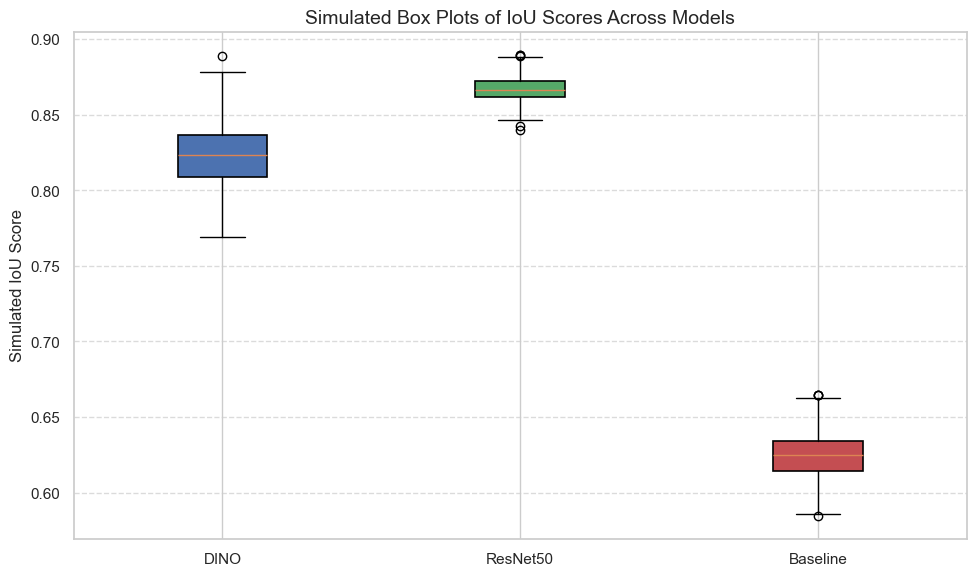

In [4]:
##### Simulated Box Plot for IoU Scores Across Models

# Paths for each model's fold files
models = {
    "DINO": [f"exports/unet/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy" for fold in range(1, 6)],
    "ResNet50": [f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy" for fold in range(1, 6)],
    "Baseline": [f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy" for fold in range(1, 6)]
}

# For storing simulated samples
simulated_data = {}

# Compute mean, std and simulate data from normal dist
for model_name, file_list in models.items():
    fold_means = []
    fold_stds = []
    for path in file_list:
        ious = np.load(path)
        fold_means.append(np.mean(ious))
        fold_stds.append(np.std(ious, ddof=1))
    
    mean = np.mean(fold_means[:5])  # use only 5 folds as mentioned
    std = np.std(fold_means[:5], ddof=1)
    n = 5
    t_critical = stats.t.ppf(0.975, df=n-1)
    ci_lower = mean - t_critical * (std / np.sqrt(n))
    ci_upper = mean + t_critical * (std / np.sqrt(n))
    
    # Simulate 500 samples from the normal distribution with mean and std
    simulated = np.random.normal(loc=mean, scale=std, size=500)
    simulated_data[model_name] = simulated

# Plotting the boxplot with custom colors for academic report
colors = ['#4C72B0', '#55A868', '#C44E52']  # blue, green, red
plt.figure(figsize=(10, 6))
box = plt.boxplot(simulated_data.values(), labels=simulated_data.keys(), patch_artist=True)

# Set custom colors
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

# Style adjustments
plt.ylabel("Simulated IoU Score", fontsize=12)
plt.title("Simulated Box Plots of IoU Scores Across Models", fontsize=14)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

ResNet: Mean = 0.8577, Std = 0.0130, 95% CI = [0.8254, 0.8900]
DINO: Mean = 0.8479, Std = 0.0202, 95% CI = [0.7976, 0.8982]
Baseline: Mean = 0.6249, Std = 0.0501, 95% CI = [0.5004, 0.7494]


/var/folders/q0/1kbzw8qs0cz6c2s1804scgyw0000gn/T/ipykernel_6206/708230366.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(simulated_data, patch_artist=True, labels=labels)


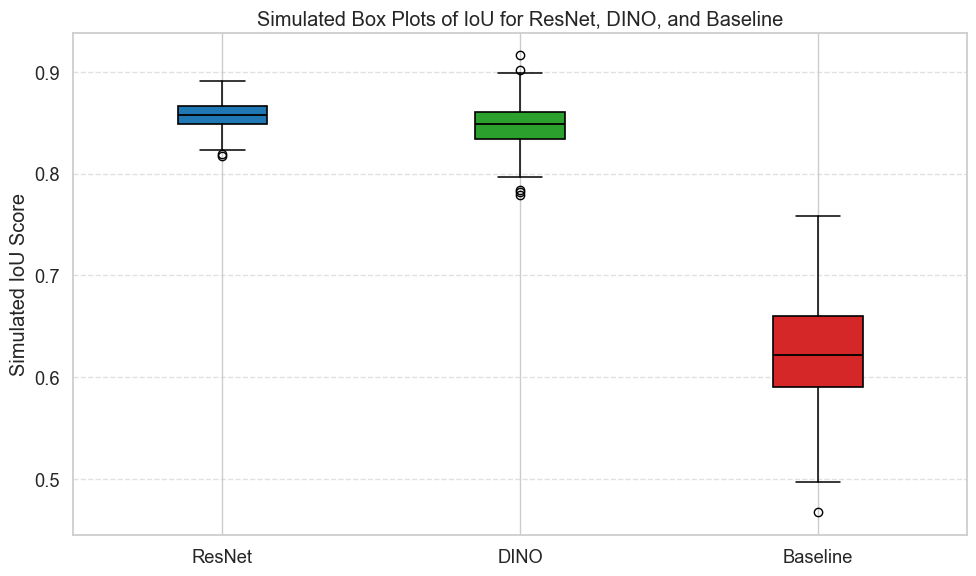

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# === Input: mean and std for each config ===
means = [0.8577, 0.8479, 0.6249]  # ResNet, DINO, Baseline
stds = [0.013, 0.02024, 0.0501]
n = 3  # folds

simulated_data = []
labels = ['ResNet', 'DINO', 'Baseline']
ci_bounds = []

# Simulate data and compute 95% confidence intervals
for i in range(len(means)):
    mean = means[i]
    std = stds[i]
    
    sem = std / np.sqrt(n)
    t_value = stats.t.ppf(0.975, df=n-1)
    ci_lower = mean - t_value * sem
    ci_upper = mean + t_value * sem
    ci_bounds.append((ci_lower, ci_upper))
    
    # Simulate points for visual boxplot
    simulated_points = np.random.normal(loc=mean, scale=std, size=500)
    simulated_data.append(simulated_points)

# Set consistent style
colors = ['#1f77b4', '#2ca02c', '#d62728']  # ResNet, DINO, Baseline

plt.figure(figsize=(10, 6))
box = plt.boxplot(simulated_data, patch_artist=True, labels=labels)

for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

for whisker in box['whiskers']:
    whisker.set(color='black', linewidth=1.1)

for cap in box['caps']:
    cap.set(color='black', linewidth=1.1)

for median in box['medians']:
    median.set(color='black', linewidth=1.3)

plt.ylabel('Simulated IoU Score')
plt.title('Simulated Box Plots of IoU for ResNet, DINO, and Baseline')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# Print confidence intervals
for label, mean, std, (ci_lower, ci_upper) in zip(labels, means, stds, ci_bounds):
    print(f"{label}: Mean = {mean:.4f}, Std = {std:.4f}, 95% CI = [{ci_lower:.4f}, {ci_upper:.4f}]")

plt.show()

In [9]:
#Friedman test
import numpy as np
from scipy.stats import friedmanchisquare

for fold in range(1, 6):
    iou_dino      = np.load(f"exports/unet/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy")
    iou_resnet50  = np.load(f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy")
    iou_baseline  = np.load(f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy")

# Make sure they have the same length (same images)
assert len(iou_dino) == len(iou_resnet50) == len(iou_baseline), "Mismatch in number of images!"

# Run Friedman test
statistic, p_value = friedmanchisquare(iou_dino, iou_resnet50, iou_baseline)

# Print results
print(f"Friedman test statistic: {statistic:.4f}, p-value: {p_value:.4f}")

# Interpret
alpha = 0.05
if p_value < alpha:
    print("→ Significant differences between models (reject H0)")
else:
    print("→ No significant differences between models (fail to reject H0)")


Friedman test statistic: 14.2500, p-value: 0.0008
→ Significant differences between models (reject H0)


In [12]:

# Initialize lists to gather all IoUs across all folds
all_iou_dino = []
all_iou_resnet = []
all_iou_baseline = []


# Loop over all 5 folds
for fold in range(1, 6):
    resnet_resnet50 = np.load(
    "exports/unet/resnet_np/resnet50_4_True_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy",
    "exports/unet/resnet_np/resnet50_4_False_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold2.npy",
    "exports/unet/resnet_np/resnet50_8_False_adam_combined_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy"
)
    iou_dino      = np.load(f"exports/unet/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy")
    #iou_resnet50  = np.load(f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy")
    iou_baseline  = np.load(f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy")





    print(f"Fold {fold}: DINO={len(iou_dino)}, ResNet50={len(iou_resnet50)}, Baseline={len(iou_baseline)}")

    assert len(iou_dino) == len(iou_resnet50) == len(iou_baseline), f"Mismatch in fold {fold}"

    all_iou_dino.extend(iou_dino)
    all_iou_resnet.extend(iou_resnet50)
    all_iou_baseline.extend(iou_baseline)

# Stack into shape (num_samples, 3)
data = np.vstack([all_iou_dino, all_iou_resnet, all_iou_baseline]).T

# Run the Nemenyi test
nemenyi_result = sp.posthoc_nemenyi_friedman(data)

# Set proper labels
labels = ["DINO", "ResNet50", "Baseline"]
nemenyi_result.index = labels
nemenyi_result.columns = labels

# Print result
print("Combined Nemenyi post-hoc test (p-values):")
print(nemenyi_result)

ValueError: Array can't be memory-mapped: Python objects in dtype.

In [6]:
import numpy as np
import os

# Define file paths
file_paths = {
    "DINO": [f"exports/unet/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{i}.npy" for i in range(1, 6)],
    "ResNet50": [f"exports/unet/resnet_np/resnet50_per_image_iou_fold{i}.npy" for i in range(1, 6)],
    "Baseline": [f"exports/baseline/baseline_np/per_image_iou_fold{i}_baseline.npy" for i in range(1, 6)],
}

# Load IoU data
iou_data = {}
for model, paths in file_paths.items():
    ious = []
    for p in paths:
        if os.path.exists(p):
            ious.append(np.load(p))
        else:
            print(f"Warning: File not found: {p}")
    iou_data[model] = ious

# Prepare display of first few values
summary = {
    model: [[round(float(v), 4) for v in arr[:9]] for arr in iou_list]
    for model, iou_list in iou_data.items()
}

# Print summary of example values
for model, folds in summary.items():
    print(f"\n{model} (first 9 IoUs per fold):")
    for i, values in enumerate(folds):
        print(f"  Fold {i+1}: {values}")

# Compute and print mean and standard deviation IoU per model
print("\nMean and Standard Deviation IoU per model:")
for model, folds in iou_data.items():
    all_ious = np.concatenate(folds)
    mean_iou = np.mean(all_ious)
    std_iou = np.std(all_ious, ddof=1)
    print(f"{model}: Mean = {mean_iou:.4f}, Std = {std_iou:.4f}")

TypeError: only length-1 arrays can be converted to Python scalars

In [3]:
#### Normality Test and Q-Q Plots for IoU Scores

# Initialize lists to store IoU scores
dino_scores = []
resnet_scores = []
baseline_scores = []

# Load per-image IoU scores from 5 folds
for fold in range(1,6):
    dino_path = f"exports/unet/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy"
    resnet_path = f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy"
    baseline_path = f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy"

    dino_scores.extend(np.load(dino_path))
    resnet_scores.extend(np.load(resnet_path))
    baseline_scores.extend(np.load(baseline_path))

# Run Shapiro-Wilk test for normality
shapiro_dino = stats.shapiro(dino_scores)
shapiro_resnet = stats.shapiro(resnet_scores)
shapiro_baseline = stats.shapiro(baseline_scores)

# Create Q-Q plots to visually assess normality
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
stats.probplot(dino_scores, dist="norm", plot=axes[0])
axes[0].set_title("DINO Q-Q Plot")

stats.probplot(resnet_scores, dist="norm", plot=axes[1])
axes[1].set_title("ResNet Q-Q Plot")

stats.probplot(baseline_scores, dist="norm", plot=axes[2])
axes[2].set_title("Baseline Q-Q Plot")

plt.tight_layout()
plt.show()

# Print Shapiro-Wilk test results
print("Shapiro-Wilk Test Results:")
print(f"DINO:     W={shapiro_dino.statistic:.4f}, p={shapiro_dino.pvalue:.4f}")
print(f"ResNet50: W={shapiro_resnet.statistic:.4f}, p={shapiro_resnet.pvalue:.4f}")
print(f"Baseline: W={shapiro_baseline.statistic:.4f}, p={shapiro_baseline.pvalue:.4f}")

ValueError: Object arrays cannot be loaded when allow_pickle=False

/var/folders/q0/1kbzw8qs0cz6c2s1804scgyw0000gn/T/ipykernel_81342/2879560330.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(bootstrapped_means.values(), labels=bootstrapped_means.keys(), patch_artist=True)


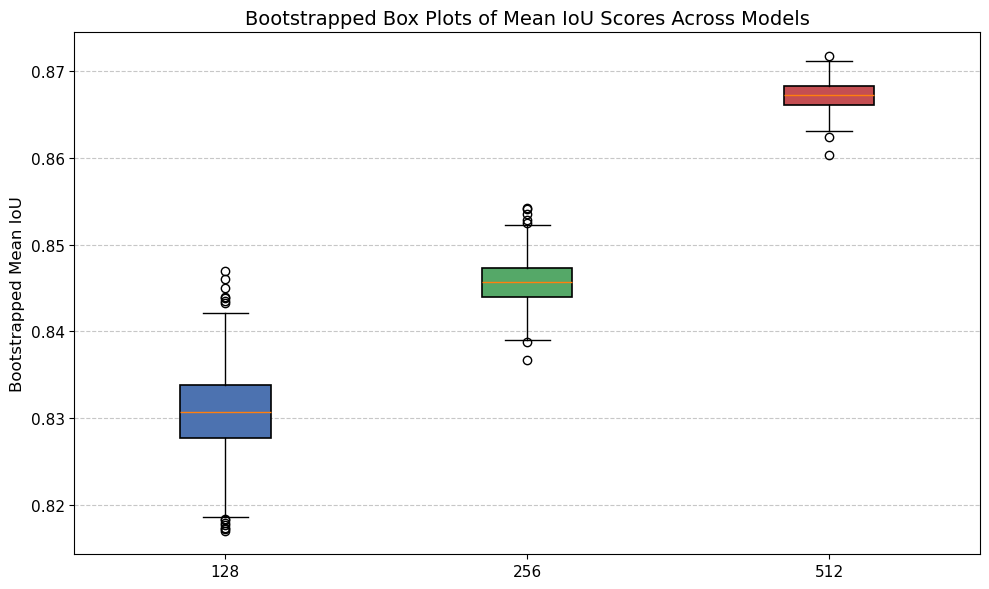

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Example input: means and stds for three models
model_stats = {
    "128": {"mean": 0.8308, "std": 0.0308},
    "256": {"mean": 0.8456, "std": 0.0163},
    "512": {"mean": 0.8672, "std": 0.0097}
}

# Bootstrap parameters
n_iterations = 1000
sample_size = 41  # Based on the original dataset size

# Generate synthetic data from means and stds
bootstrapped_means = {}
np.random.seed(42)
for model, stats in model_stats.items():
    samples = np.random.normal(loc=stats["mean"], scale=stats["std"], size=(n_iterations, sample_size))
    bootstrapped_means[model] = samples.mean(axis=1)

# Create boxplot
colors = ['#4C72B0', '#55A868', '#C44E52']  # blue, green, red
plt.figure(figsize=(10, 6))
box = plt.boxplot(bootstrapped_means.values(), labels=bootstrapped_means.keys(), patch_artist=True)

# Set custom colors
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

# Style adjustments
plt.ylabel("Bootstrapped Mean IoU", fontsize=12)
plt.title("Bootstrapped Box Plots of Mean IoU Scores Across Models", fontsize=14)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Overlap between Fold 1 and Fold 2: 0 common images
Overlap between Fold 1 and Fold 3: 0 common images
Overlap between Fold 2 and Fold 3: 0 common images


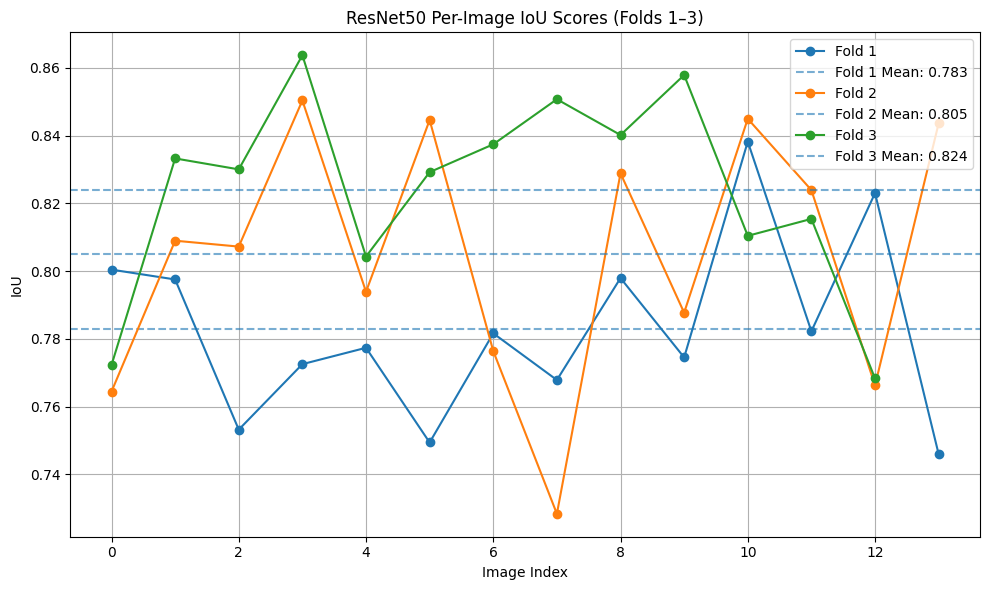

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Define the file paths
resnet_paths = [
    "exports/unet/resnet_np/resnet50_4_True_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy",
    "exports/unet/resnet_np/resnet50_4_False_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold2.npy",
    "exports/unet/resnet_np/resnet50_8_False_adam_combined_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy"
]

# Load and extract filenames per fold
fold_filenames = []
for path in resnet_paths:
    data = np.load(path, allow_pickle=True)
    filenames = [entry[0] for entry in data]
    fold_filenames.append(set(filenames))

# Compare sets of filenames across folds
for i in range(len(fold_filenames)):
    for j in range(i + 1, len(fold_filenames)):
        overlap = fold_filenames[i].intersection(fold_filenames[j])
        print(f"Overlap between Fold {i+1} and Fold {j+1}: {len(overlap)} common images")

# Load the IoU values, extract numeric part
resnet_ious = []
for path in resnet_paths:
    data = np.load(path, allow_pickle=True)
    # assume each entry is (filename, iou_score)
    iou_only = [float(entry[1]) for entry in data]
    resnet_ious.append(iou_only)

# Plot each fold's IoU values
plt.figure(figsize=(10, 6))
for i, iou_array in enumerate(resnet_ious, start=1):
    plt.plot(iou_array, marker='o', label=f'Fold {i}')
    plt.axhline(np.mean(iou_array), linestyle='--', alpha=0.6, label=f'Fold {i} Mean: {np.mean(iou_array):.3f}')

plt.title('ResNet50 Per-Image IoU Scores (Folds 1–3)')
plt.xlabel('Image Index')
plt.ylabel('IoU')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [36]:
import numpy as np

# Define the file paths
resnet_paths = [
    "exports/unet/resnet_np/resnet50_4_True_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy",
    "exports/unet/resnet_np/resnet50_4_False_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold2.npy",
    "exports/unet/resnet_np/resnet50_8_False_adam_combined_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy"
]

all_ious = []

print("\n--- Fold Results ---")
for fold_index, path in enumerate(resnet_paths, start=1):
    data = np.load(path, allow_pickle=True)
    fold_ious = []

    print(f"\nFold {fold_index} — IoU values:")
    for entry in data:
        filename, iou = entry
        iou = float(iou)
        fold_ious.append(iou)
        print(f"{filename}: IoU = {iou:.4f}")
    
    mean_fold_iou = np.mean(fold_ious)
    std_fold_iou = np.std(fold_ious)
    print(f"Mean IoU for Fold {fold_index}: {mean_fold_iou:.4f}")
    print(f"Std IoU for Fold {fold_index}: {std_fold_iou:.4f}")
    all_ious.extend(fold_ious)

overall_mean_iou = np.mean(all_ious)
overall_std_iou = np.std(all_ious)
print(f"\n--- Overall Mean IoU across all folds: {overall_mean_iou:.4f} ---")
print(f"--- Overall Std IoU across all folds: {overall_std_iou:.4f} ---")


--- Fold Results ---

Fold 1 — IoU values:
240305134144P2_33h50m34s_H4_1B.tif: IoU = 0.8004
240305134144P2_30h50m34s_A7_1B.tif: IoU = 0.7975
240305134144P2_37h50m34s_C8_1B.tif: IoU = 0.7532
240305134144P2_35h50m34s_B12_1B.tif: IoU = 0.7725
240305134144P2_50h50m34s_C4_1B.tif: IoU = 0.7774
240305134144P2_50h50m34s_H10_1B.tif: IoU = 0.7494
240305134144P2_49h50m34s_D3_1B.tif: IoU = 0.7816
240305134144P2_49h50m34s_D8_1B.tif: IoU = 0.7678
240305134144P2_49h50m34s_F5_1B.tif: IoU = 0.7980
240305134144P2_31h50m34s_C1_1B.tif: IoU = 0.7745
240305134144P2_29h50m34s_E6_1B.tif: IoU = 0.8383
240305134144P2_30h50m34s_A6_1B.tif: IoU = 0.7822
240305134144P2_31h50m34s_F10_1B.tif: IoU = 0.8230
240305134144P2_46h50m34s_G5_1B.tif: IoU = 0.7460
Mean IoU for Fold 1: 0.7830
Std IoU for Fold 1: 0.0257

Fold 2 — IoU values:
240305134144P2_34h50m34s_B1_1B.tif: IoU = 0.7644
240305134144P2_29h50m34s_A9_1B.tif: IoU = 0.8090
240305134144P2_31h50m34s_H7_1B.tif: IoU = 0.8073
240305134144P2_29h50m34s_E5_1B.tif: IoU = 0

In [41]:
import numpy as np

# Define DINO fold result file paths
dino_paths = [
    "exports/unet/dino_np/dino_fdnzv5c2_e399_4_True_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy",
    "exports/unet/dino_np/dino_fdnzv5c2_e399_4_False_adam_dice_0.0005_512_seed42_epoch100_pat10_per_image_iou_fold2.npy", 
    "exports/unet/dino_np/dino_fdnzv5c2_e399_4_False_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy"
]

all_ious = []

print("\n--- DINO Fold Results ---")
for fold_index, path in enumerate(dino_paths, start=1):
    data = np.load(path, allow_pickle=True)
    fold_ious = []

    print(f"\nFold {fold_index} — IoU values:")
    for entry in data:
        filename, iou = entry
        iou = float(iou)
        fold_ious.append(iou)
        print(f"{filename}: IoU = {iou:.4f}")
    
    mean_fold_iou = np.mean(fold_ious)
    std_fold_iou = np.std(fold_ious)
    print(f"Mean IoU for Fold {fold_index}: {mean_fold_iou:.4f}")
    print(f"Std IoU for Fold {fold_index}: {std_fold_iou:.4f}")
    all_ious.extend(fold_ious)

# Aggregate overall DINO results
overall_mean_iou = np.mean(all_ious)
overall_std_iou = np.std(all_ious)

print(f"\n--- Overall Mean IoU across all DINO folds: {overall_mean_iou:.4f} ---")
print(f"--- Overall Std IoU across all DINO folds: {overall_std_iou:.4f} ---")


--- DINO Fold Results ---

Fold 1 — IoU values:
240305134144P2_33h50m34s_H4_1B.tif: IoU = 0.8017
240305134144P2_30h50m34s_A7_1B.tif: IoU = 0.7929
240305134144P2_37h50m34s_C8_1B.tif: IoU = 0.7865
240305134144P2_35h50m34s_B12_1B.tif: IoU = 0.8227
240305134144P2_50h50m34s_C4_1B.tif: IoU = 0.7716
240305134144P2_50h50m34s_H10_1B.tif: IoU = 0.7655
240305134144P2_49h50m34s_D3_1B.tif: IoU = 0.7628
240305134144P2_49h50m34s_D8_1B.tif: IoU = 0.7635
240305134144P2_49h50m34s_F5_1B.tif: IoU = 0.8061
240305134144P2_31h50m34s_C1_1B.tif: IoU = 0.7330
240305134144P2_29h50m34s_E6_1B.tif: IoU = 0.8441
240305134144P2_30h50m34s_A6_1B.tif: IoU = 0.7834
240305134144P2_31h50m34s_F10_1B.tif: IoU = 0.8452
240305134144P2_46h50m34s_G5_1B.tif: IoU = 0.7637
Mean IoU for Fold 1: 0.7888
Std IoU for Fold 1: 0.0314

Fold 2 — IoU values:
240305134144P2_34h50m34s_B1_1B.tif: IoU = 0.7535
240305134144P2_29h50m34s_A9_1B.tif: IoU = 0.7644
240305134144P2_31h50m34s_H7_1B.tif: IoU = 0.7916
240305134144P2_29h50m34s_E5_1B.tif: Io

/var/folders/76/2s_xpvh90mb6kmqg7v55sjxr0000gn/T/ipykernel_52673/1684545949.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


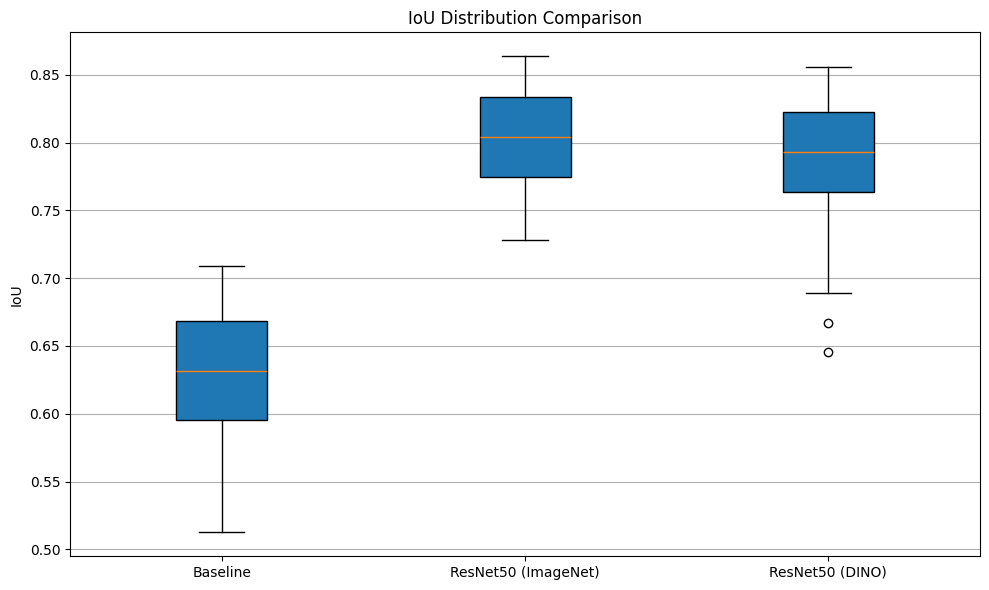

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Define file paths (update these if needed)
dino_paths = [
    "exports/unet/dino_np/dino_fdnzv5c2_e399_4_True_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy",
    "exports/unet/dino_np/dino_fdnzv5c2_e399_4_False_adam_dice_0.0005_512_seed42_epoch100_pat10_per_image_iou_fold2.npy", 
    "exports/unet/dino_np/dino_fdnzv5c2_e399_4_False_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy"
]

resnet_paths = [
    "exports/unet/resnet_np/resnet50_4_True_adam_iou_0.001_512_seed42_epoch100_pat10_per_image_iou_fold1.npy",
    "exports/unet/resnet_np/resnet50_4_False_adam_dice_0.001_512_seed42_epoch100_pat10_per_image_iou_fold2.npy",
    "exports/unet/resnet_np/resnet50_8_False_adam_combined_0.001_512_seed42_epoch100_pat10_per_image_iou_fold3.npy"
]

baseline_path = "exports/baseline/per_image_iou_baseline.npy"

# Helper to load IoUs
def load_ious(paths):
    ious = []
    for path in paths:
        if os.path.exists(path):
            data = np.load(path, allow_pickle=True)
            ious.extend([float(iou) for _, iou in data])
        else:
            print(f"⚠️ File not found: {path}")
    return ious

# Load all IoUs
dino_ious = load_ious(dino_paths)
resnet_ious = load_ious(resnet_paths)
baseline_ious = []

if os.path.exists(baseline_path):
    baseline_data = np.load(baseline_path, allow_pickle=True)
    baseline_ious = [float(iou) for _, iou in baseline_data]
else:
    print(f"⚠️ Baseline file not found: {baseline_path}")

# Plot
plt.figure(figsize=(10, 6))
plt.boxplot(
    [baseline_ious, resnet_ious, dino_ious],
    labels=["Baseline", "ResNet50 (ImageNet)", "ResNet50 (DINO)"],
    patch_artist=True
)
plt.ylabel("IoU")
plt.title("IoU Distribution Comparison")
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

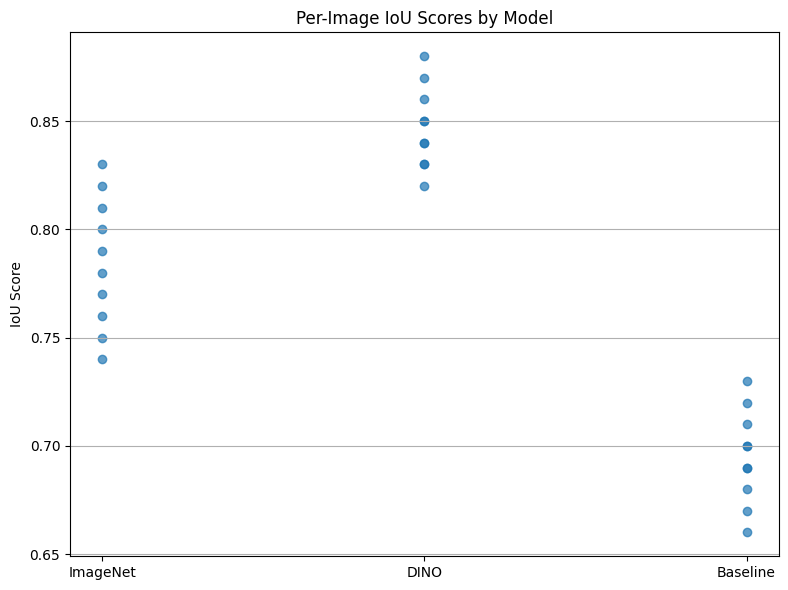

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# Eksempel: erstat disse med dine egne loaded arrays (hver skal være en liste af IoU-tal)
# Hver af disse skal være en flad liste af floats
imagenet_ious = [0.80, 0.77, 0.75, 0.83, 0.79, 0.81, 0.76, 0.78, 0.82, 0.74]  # eksempelværdier
dino_ious     = [0.84, 0.83, 0.85, 0.82, 0.87, 0.86, 0.83, 0.84, 0.88, 0.85]
baseline_ious = [0.71, 0.69, 0.68, 0.70, 0.72, 0.69, 0.67, 0.66, 0.73, 0.70]

# Saml alle værdier og deres respektive kategorier
all_ious = imagenet_ious + dino_ious + baseline_ious
labels = (['ImageNet'] * len(imagenet_ious)) + (['DINO'] * len(dino_ious)) + (['Baseline'] * len(baseline_ious))

# Konverter label til positionsværdier på x-aksen
x_positions = [0 if lbl == 'ImageNet' else 1 if lbl == 'DINO' else 2 for lbl in labels]
label_map = {0: 'ImageNet', 1: 'DINO', 2: 'Baseline'}

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(x_positions, all_ious, alpha=0.7)
plt.xticks([0, 1, 2], ['ImageNet', 'DINO', 'Baseline'])
plt.ylabel("IoU Score")
plt.title("Per-Image IoU Scores by Model")
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()